# CS5785 Assignment 1 - Programming Exercises, Part I
## House Prices

In this notebook, I work through the six questions in Part I using the Kaggle House Prices dataset. I put the explanation, code, and output for each question in its own section.

## 1. Load the Kaggle data

I downloaded `train.csv`, `test.csv`, `sample_submission.csv`, and `data_description.txt` from Kaggle and saved them in the same folder as this notebook. The variable I want to predict is `SalePrice`, which is included in the training data but not in the test data.

In [1]:
from pathlib import Path
import math
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
plt.style.use('seaborn-v0_8-whitegrid')
DATA_DIR = Path('.')

train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')

print(f'Training shape: {train.shape}')
print(f'Test shape:     {test.shape}')
print(f'SalePrice only in training data: {"SalePrice" in train.columns and "SalePrice" not in test.columns}')
train[['Id', 'GrLivArea', 'Neighborhood', 'HouseStyle', 'CentralAir', 'SalePrice']].head()

Training shape: (1460, 81)
Test shape:     (1459, 80)
SalePrice only in training data: True


,Id,GrLivArea,Neighborhood,HouseStyle,CentralAir,SalePrice
0,1,1710,CollgCr,2Story,Y,208500
1,2,1262,Veenker,1Story,Y,181500
2,3,1786,CollgCr,2Story,Y,223500
3,4,1717,Crawfor,2Story,Y,140000
4,5,2198,NoRidge,2Story,Y,250000


## 2. Continuous and categorical features

For continuous features, I chose:

1. `GrLivArea`: above-ground living area in square feet.
2. `LotArea`: lot size in square feet.
3. `GarageArea`: garage size in square feet.

For categorical features, I chose:

1. `Neighborhood`: physical location within Ames.
2. `HouseStyle`: dwelling style.
3. `CentralAir`: whether the house has central air conditioning.

I used `GrLivArea` and `HouseStyle` for the plots below. Since `HouseStyle` consists of separate categories instead of a continuous range of numbers, I used a bar-style frequency plot for it.

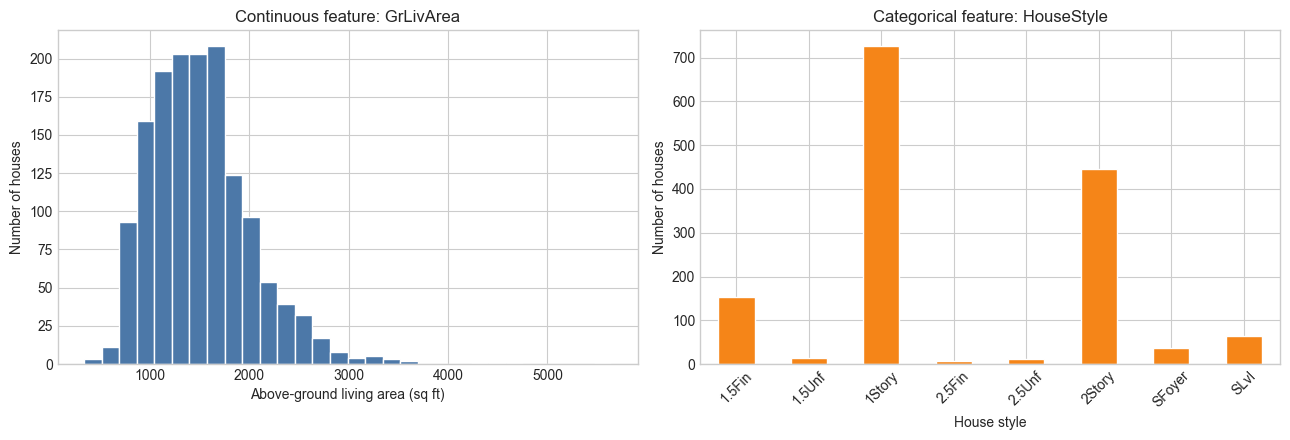

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(train['GrLivArea'], bins=30, color='#4C78A8', edgecolor='white')
axes[0].set_title('Continuous feature: GrLivArea')
axes[0].set_xlabel('Above-ground living area (sq ft)')
axes[0].set_ylabel('Number of houses')

train['HouseStyle'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color='#F58518', edgecolor='white'
)
axes[1].set_title('Categorical feature: HouseStyle')
axes[1].set_xlabel('House style')
axes[1].set_ylabel('Number of houses')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

From the first plot, most houses have a moderate living area, but there are a few houses with much larger values, so the distribution is skewed to the right. In the second plot, `1Story` and `2Story` are clearly the most common house styles.

## 3. Data preprocessing

Before fitting a model, I cleaned and transformed the data in the following way:

1. **Remove `Id` and separate `SalePrice`.** `Id` is just an identifier, so I did not use it as a feature. `SalePrice` is separated because it is the value the model is trying to predict.
2. **Fix categories that happen to be stored as numbers.** `MSSubClass` is a code for the type of house, not a numerical measurement. `MoSold` is also better treated as a category because it represents the month of sale. I converted both of them to categorical variables. I kept `YrSold` as a numeric variable to represent a simple time trend. I also kept `OverallQual` and `OverallCond` as ordered numeric ratings.
3. **Fill missing numeric values with the training median.** I used the median because it is less affected by extreme values than the mean. The test data is filled using medians calculated only from the training data.
4. **Fill missing categorical values with `Missing`.** For some housing features, a missing entry can mean that the feature does not exist, such as having no alley or fireplace. Keeping a separate `Missing` category allows the model to use that information.
5. **Standardize the numeric features.** The features use very different units, such as years, square feet, and counts. Standardizing them puts them on similar scales and makes the matrix calculation more stable.
6. **One-hot encode the categorical features.** A linear regression model needs numerical inputs, but assigning ordinary numbers to categories would create an artificial order. I also made sure the test data has the same dummy columns as the training data.

The code below applies these steps to all of the available features. For the OLS model in Question 5, I use a smaller group of numerical features so that the from-scratch implementation stays manageable and easy to follow.

In [3]:
X_raw = train.drop(columns=['SalePrice', 'Id']).copy()
X_test_raw = test.drop(columns=['Id']).copy()
y = train['SalePrice'].astype(float).copy()

numeric_coded_categories = ['MSSubClass', 'MoSold']
for column in numeric_coded_categories:
    X_raw[column] = X_raw[column].astype('string')
    X_test_raw[column] = X_test_raw[column].astype('string')

numeric_columns = X_raw.select_dtypes(include='number').columns.tolist()
categorical_columns = X_raw.select_dtypes(exclude='number').columns.tolist()
assert set(numeric_coded_categories).issubset(categorical_columns)

X_numeric = X_raw[numeric_columns].copy()
X_test_numeric = X_test_raw[numeric_columns].copy()
numeric_medians = X_numeric.median()
X_numeric = X_numeric.fillna(numeric_medians)
X_test_numeric = X_test_numeric.fillna(numeric_medians)

numeric_means = X_numeric.mean()
numeric_stds = X_numeric.std(ddof=0).replace(0, 1)
X_numeric = (X_numeric - numeric_means) / numeric_stds
X_test_numeric = (X_test_numeric - numeric_means) / numeric_stds

X_categorical = X_raw[categorical_columns].fillna('Missing')
X_test_categorical = X_test_raw[categorical_columns].fillna('Missing')
X_categorical = pd.get_dummies(X_categorical, dtype=float)
X_test_categorical = pd.get_dummies(X_test_categorical, dtype=float)
X_test_categorical = X_test_categorical.reindex(columns=X_categorical.columns, fill_value=0.0)

X_processed = pd.concat([X_numeric, X_categorical], axis=1)
X_test_processed = pd.concat([X_test_numeric, X_test_categorical], axis=1)

print(f'Reclassified as categorical: {numeric_coded_categories}')
print(f'Numeric columns:             {len(numeric_columns)}')
print(f'Categorical columns:         {len(categorical_columns)}')
print(f'Processed train:     {X_processed.shape}')
print(f'Processed test:      {X_test_processed.shape}')
print(f'Total missing after preprocessing: {int(X_processed.isna().sum().sum())}')

Reclassified as categorical: ['MSSubClass', 'MoSold']
Numeric columns:             34
Categorical columns:         45
Processed train:     (1460, 328)
Processed test:      (1459, 328)
Total missing after preprocessing: 0


## 4. One-hot encoding

Features such as `Neighborhood`, `HouseStyle`, and `Exterior1st` do not have a natural order. If I replaced their values with numbers like 1, 2, and 3, the model would treat those numbers as meaningful distances. One-hot encoding avoids this problem by creating a separate 0/1 column for each category.

For a simple example, I used one-hot encoding on `CentralAir`, which originally contains `Y` and `N`. This creates the two binary columns `CentralAir_N` and `CentralAir_Y`.

,CentralAir,CentralAir_N,CentralAir_Y
0,N,1,0
1,Y,0,1


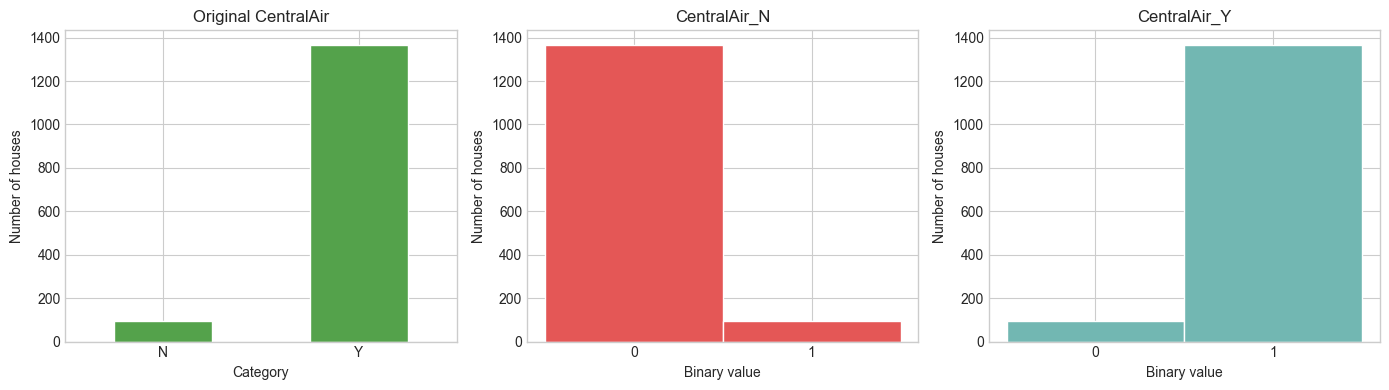

In [4]:
central_air_ohe = pd.get_dummies(train['CentralAir'], prefix='CentralAir', dtype=int)
central_air_mapping = pd.concat([train[['CentralAir']], central_air_ohe], axis=1)
display(central_air_mapping.drop_duplicates().sort_values('CentralAir').reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
train['CentralAir'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='#54A24B', edgecolor='white'
)
axes[0].set_title('Original CentralAir')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Number of houses')
axes[0].tick_params(axis='x', rotation=0)

for ax, column, color in zip(axes[1:], central_air_ohe.columns, ['#E45756', '#72B7B2']):
    ax.hist(central_air_ohe[column], bins=[-0.5, 0.5, 1.5], color=color, edgecolor='white')
    ax.set_xticks([0, 1])
    ax.set_title(column)
    ax.set_xlabel('Binary value')
    ax.set_ylabel('Number of houses')

plt.tight_layout()
plt.show()

A house with central air is represented by `(CentralAir_N, CentralAir_Y) = (0, 1)`, while a house without central air is represented by `(1, 0)`. If both columns were used in a regression model with an intercept, I would normally drop one of them because one column can be determined exactly from the other.

## 5. Building ordinary least squares (OLS)

I chose eight numerical features that I expected to be related to house price: `OverallQual`, `GrLivArea`, `GarageCars`, `GarageArea`, `TotalBsmtSF`, `1stFlrSF`, `FullBath`, and `YearBuilt`. These features describe the quality, size, garage, basement, bathrooms, and age of a house. I did not include `Id` because it is only an identifier. I also limited the number of features because the OLS solver has to be implemented from scratch for this question.

The OLS estimate solves the normal equations

$$\hat{\beta}=(X^T X)^{-1}X^T y.$$

For this implementation, I did not use external libraries or packages to implement OLS. Pandas was used only for data loading, preprocessing, and output, not for implementing the OLS model. I calculated $X^TX$ and $X^Ty$ using Python loops, then solved the resulting system using Gauss-Jordan elimination with partial pivoting. I standardized the selected features first using statistics from the training set.

In [5]:
MODEL_FEATURES = [
    'OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea',
    'TotalBsmtSF', '1stFlrSF', 'FullBath', 'YearBuilt'
]

def prepare_model_features(train_frame, test_frame, columns):
    train_x = train_frame[columns].copy()
    test_x = test_frame[columns].copy()
    medians = train_x.median()
    train_x = train_x.fillna(medians)
    test_x = test_x.fillna(medians)
    means = train_x.mean()
    stds = train_x.std(ddof=0).replace(0, 1)
    train_x = (train_x - means) / stds
    test_x = (test_x - means) / stds
    return train_x, test_x, medians, means, stds

def gauss_jordan_solve(matrix, vector, tolerance=1e-12):
    n = len(vector)
    augmented = [list(map(float, matrix[i])) + [float(vector[i])] for i in range(n)]

    for column in range(n):
        pivot_row = max(range(column, n), key=lambda row: abs(augmented[row][column]))
        if abs(augmented[pivot_row][column]) < tolerance:
            raise ValueError('The normal-equation matrix is singular.')
        augmented[column], augmented[pivot_row] = augmented[pivot_row], augmented[column]

        pivot = augmented[column][column]
        augmented[column] = [value / pivot for value in augmented[column]]

        for row in range(n):
            if row == column:
                continue
            factor = augmented[row][column]
            if factor != 0:
                augmented[row] = [
                    augmented[row][j] - factor * augmented[column][j]
                    for j in range(n + 1)
                ]

    return [augmented[i][-1] for i in range(n)]

class OrdinaryLeastSquaresScratch:
    def fit(self, X, y_values):
        rows = [[1.0] + [float(value) for value in row] for row in X]
        targets = [float(value) for value in y_values]
        n_columns = len(rows[0])

        xtx = [[0.0 for _ in range(n_columns)] for _ in range(n_columns)]
        xty = [0.0 for _ in range(n_columns)]
        for row, target in zip(rows, targets):
            for j in range(n_columns):
                xty[j] += row[j] * target
                for k in range(n_columns):
                    xtx[j][k] += row[j] * row[k]

        self.coefficients_ = gauss_jordan_solve(xtx, xty)
        return self

    def predict(self, X):
        predictions = []
        for row in X:
            values = [1.0] + [float(value) for value in row]
            predictions.append(sum(coef * value for coef, value in zip(self.coefficients_, values)))
        return predictions

def mean_squared_error_scratch(actual, predicted):
    pairs = list(zip(actual, predicted))
    return sum((float(a) - float(p)) ** 2 for a, p in pairs) / len(pairs)

def r2_score_scratch(actual, predicted):
    actual_values = [float(value) for value in actual]
    mean_actual = sum(actual_values) / len(actual_values)
    residual_sum = sum((a - float(p)) ** 2 for a, p in zip(actual_values, predicted))
    total_sum = sum((a - mean_actual) ** 2 for a in actual_values)
    return 1.0 - residual_sum / total_sum

In [6]:
X_model, X_test_model, model_medians, model_means, model_stds = prepare_model_features(
    train, test, MODEL_FEATURES
)

ols = OrdinaryLeastSquaresScratch().fit(X_model.values.tolist(), y.tolist())
train_predictions = ols.predict(X_model.values.tolist())
train_mse = mean_squared_error_scratch(y.tolist(), train_predictions)
train_r2 = r2_score_scratch(y.tolist(), train_predictions)

coefficient_table = pd.DataFrame({
    'term': ['Intercept'] + MODEL_FEATURES,
    'coefficient': ols.coefficients_
})

print(f'Training MSE: {train_mse:,.2f}')
print(f'Training RMSE: {math.sqrt(train_mse):,.2f}')
print(f'Training R^2: {train_r2:.4f}')
display(coefficient_table)

Training MSE: 1,448,659,194.34
Training RMSE: 38,061.26
Training R^2: 0.7703


,term,coefficient
0,Intercept,180921.195890
1,OverallQual,28934.448763
2,GrLivArea,26866.711303
3,GarageCars,7929.782900
4,GarageArea,3112.841020
5,TotalBsmtSF,8450.935814
6,1stFlrSF,5389.894368
7,FullBath,-2994.565034
8,YearBuilt,10437.779991


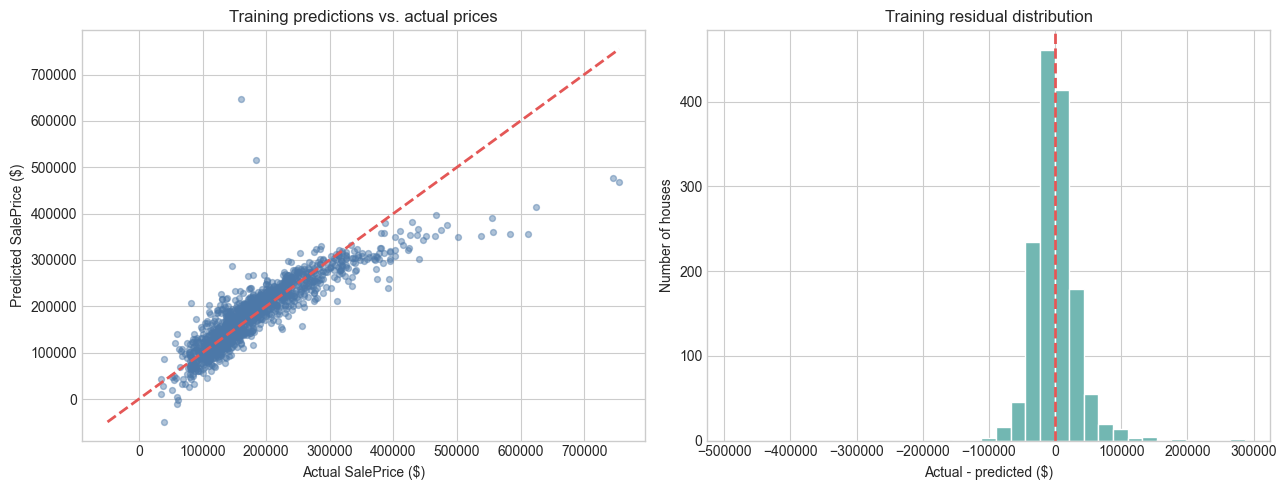

In [7]:
residuals = [float(actual) - predicted for actual, predicted in zip(y, train_predictions)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y, train_predictions, alpha=0.45, s=18, color='#4C78A8')
plot_min = min(float(y.min()), min(train_predictions))
plot_max = max(float(y.max()), max(train_predictions))
axes[0].plot([plot_min, plot_max], [plot_min, plot_max], '--', color='#E45756', linewidth=2)
axes[0].set_title('Training predictions vs. actual prices')
axes[0].set_xlabel('Actual SalePrice ($)')
axes[0].set_ylabel('Predicted SalePrice ($)')

axes[1].hist(residuals, bins=35, color='#72B7B2', edgecolor='white')
axes[1].axvline(0, color='#E45756', linestyle='--', linewidth=2)
axes[1].set_title('Training residual distribution')
axes[1].set_xlabel('Actual - predicted ($)')
axes[1].set_ylabel('Number of houses')

plt.tight_layout()
plt.show()

These scores are calculated on the same training data used to fit the model, as requested in the question. Because of this, they are probably better than the model's performance on new data. The scatter plot shows that the model follows the general price pattern, but it makes larger errors for some of the most expensive houses. This could be caused by outliers, missing features, or relationships that are not linear.

## 6. Training

The model above uses all 1,460 rows in the training set. I applied the same medians, means, and standard deviations from the training data to the 1,459 test rows, and then generated the test predictions. I replaced any negative prediction with zero because a house price cannot be negative. Finally, I saved the predictions using the same columns as Kaggle's sample submission.

In [8]:
test_predictions = ols.predict(X_test_model.values.tolist())
test_predictions = [max(0.0, prediction) for prediction in test_predictions]

submission = pd.DataFrame({
    'Id': test['Id'].astype(int),
    'SalePrice': test_predictions
})
submission_path = DATA_DIR / 'submission_part1.csv'
submission.to_csv(submission_path, index=False)

assert list(submission.columns) == ['Id', 'SalePrice']
assert len(submission) == len(test) == len(sample_submission)
assert submission['Id'].equals(sample_submission['Id'])
assert not submission.isna().any().any()

print(f'Saved {len(submission):,} predictions to {submission_path.resolve()}')
submission.head()

Saved 1,459 predictions to C:\Users\zhiji\Desktop\AML_HW1\submission_part1.csv


,Id,SalePrice
0,1461,114255.467603
1,1462,164857.911527
2,1463,167088.495756
3,1464,186843.093404
4,1465,222338.312800
